# Projet Analyse de données — Airbnb NYC 2019


| Étapes | Contenu | Responsable | Story Jira |
|---|---|---|---|
| 1 et 2 | Structure, types, qualité des données | Houmad | SCRUM-7 |
| 3 | Nettoyage et export | Anas Fouad | SCRUM-8 |
| 4 | Q1 — prix par arrondissement et type | Juba | SCRUM-10 |
| 5 | Q2 — top 10 des quartiers | Houmad | SCRUM-11 |
| 6 | Q3 — type ou arrondissement ? (R² et bootstrap) | Anas Fouad | SCRUM-12 |
| 7 | Q4 — disponibilité annuelle | Houmad | SCRUM-13 |
| 8 | Q5 — prix et disponibilité | Hamza | SCRUM-14 |
| 9 | Enregistrer les tableaux | Anas Fouad | SCRUM-25 |
| Tout | Exécution complète de haut en bas (reproductibilité) | Anas Fouad | SCRUM-57 |

la préparation des données (Niveaux 1 et 2), Q1 (prix médian par arrondissement et type de logement) et Q2 (top 10 des quartiers). Les questions Q3 à Q5 seront ajoutées aux sprints suivants.


In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import spearmanr, skew

FICHIER = os.path.join("..", "data", "raw", "AB_NYC_2019.csv")
DOSSIER_SORTIE = os.path.join("..", "outputs")
DOSSIER_DONNEES = os.path.join("..", "data", "processed")
SEUIL_EFFECTIF = 100       # en dessous de 100 annonces, on ne conclut pas

os.makedirs(DOSSIER_SORTIE, exist_ok=True)
os.makedirs(DOSSIER_DONNEES, exist_ok=True)
pd.set_option("display.width", 120)
pd.set_option("display.max_columns", 20)

# Ordres d'affichage et noms français
ordre_arr = ["Manhattan", "Brooklyn", "Queens", "Bronx", "Staten Island"]
ordre_types = ["Logement entier", "Chambre privée", "Chambre partagée"]
noms_types = {"Entire home/apt": "Logement entier",
              "Private room": "Chambre privée",
              "Shared room": "Chambre partagée"}


def sauver(nom):
    """Enregistre le graphique courant dans 'outputs', puis l'affiche."""
    plt.tight_layout()
    plt.savefig(os.path.join(DOSSIER_SORTIE, nom), dpi=150)
    plt.show()

## Étape 1 — Charger et regarder les données
**Responsable : Houmad · Story SCRUM-7 (Auditer les données) · sous-tâche SCRUM-20 : vérifier la structure et les types**

In [2]:
# [SCRUM-20] Structure et types
df = pd.read_csv(FICHIER)
print("Dimensions (lignes, colonnes) :", df.shape)      # attendu : 48895 lignes, 16 colonnes
print("La colonne id est unique :", df["id"].is_unique)
print("Arrondissements :", df["neighbourhood_group"].nunique(), "| Quartiers :", df["neighbourhood"].nunique())   # attendu : 5 et 221
df.head()

Dimensions (lignes, colonnes) : (48895, 16)
La colonne id est unique : True
Arrondissements : 5 | Quartiers : 221


,id,name,host_id,host_name,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,last_review,reviews_per_month,calculated_host_listings_count,availability_365
0,2539,Clean & quiet apt home by the park,2787,John,Brooklyn,Kensington,40.64749,-73.97237,Private room,149,1,9,2018-10-19,0.21,6,365
1,2595,Skylit Midtown Castle,2845,Jennifer,Manhattan,Midtown,40.75362,-73.98377,Entire home/apt,225,1,45,2019-05-21,0.38,2,355
2,3647,THE VILLAGE OF HARLEM....NEW YORK !,4632,Elisabeth,Manhattan,Harlem,40.80902,-73.94190,Private room,150,3,0,NaN,NaN,1,365
3,3831,Cozy Entire Floor of Brownstone,4869,LisaRoxanne,Brooklyn,Clinton Hill,40.68514,-73.95976,Entire home/apt,89,1,270,2019-07-05,4.64,1,194
4,5022,Entire Apt: Spacious Studio/Loft by central park,7192,Laura,Manhattan,East Harlem,40.79851,-73.94399,Entire home/apt,80,10,9,2018-11-19,0.10,1,0


In [3]:
# [SCRUM-20] Types de chaque colonne et plages de valeurs
df.info()
df[["price", "minimum_nights", "number_of_reviews", "availability_365"]].describe()

<class 'pandas.DataFrame'>
RangeIndex: 48895 entries, 0 to 48894
Data columns (total 16 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   id                              48895 non-null  int64  
 1   name                            48879 non-null  str    
 2   host_id                         48895 non-null  int64  
 3   host_name                       48874 non-null  str    
 4   neighbourhood_group             48895 non-null  str    
 5   neighbourhood                   48895 non-null  str    
 6   latitude                        48895 non-null  float64
 7   longitude                       48895 non-null  float64
 8   room_type                       48895 non-null  str    
 9   price                           48895 non-null  int64  
 10  minimum_nights                  48895 non-null  int64  
 11  number_of_reviews               48895 non-null  int64  
 12  last_review                     38843 non-n

,price,minimum_nights,number_of_reviews,availability_365
count,48895.000000,48895.000000,48895.000000,48895.000000
mean,152.720687,7.029962,23.274466,112.781327
std,240.154170,20.510550,44.550582,131.622289
min,0.000000,1.000000,0.000000,0.000000
25%,69.000000,1.000000,1.000000,0.000000
50%,106.000000,3.000000,5.000000,45.000000
75%,175.000000,5.000000,24.000000,227.000000
max,10000.000000,1250.000000,629.000000,365.000000


## Étape 2 — Qualité des données
**Responsable : Houmad · Story SCRUM-7 · sous-tâches SCRUM-21 (mesurer les problèmes de qualité) et SCRUM-22 (documenter les décisions)**

On mesure : valeurs manquantes, doublons, prix égaux à 0, prix extrêmes, `minimum_nights` inhabituels, disponibilité à 0 jour.
Le 99e centile du prix sert de seuil pour les prix extrêmes.

In [4]:
# [SCRUM-21] Mesure des problèmes de qualité
print("--- Valeurs manquantes ---")
print(df.isna().sum())
print("\nDoublons exacts :", df.duplicated().sum())
print("Prix égal à 0 :", (df["price"] == 0).sum())

seuil = df["price"].quantile(0.99)
print("99e centile du prix :", seuil)                   # attendu : 799
print("Prix au-dessus du seuil :", (df["price"] > seuil).sum())
print("minimum_nights supérieur à 365 :", (df["minimum_nights"] > 365).sum())
print("Disponibilité égale à 0 jour :", (df["availability_365"] == 0).sum())

--- Valeurs manquantes ---
id                                    0
name                                 16
host_id                               0
host_name                            21
neighbourhood_group                   0
neighbourhood                         0
latitude                              0
longitude                             0
room_type                             0
price                                 0
minimum_nights                        0
number_of_reviews                     0
last_review                       10052
reviews_per_month                 10052
calculated_host_listings_count        0
availability_365                      0
dtype: int64

Doublons exacts : 0
Prix égal à 0 : 11
99e centile du prix : 799.0
Prix au-dessus du seuil : 474
minimum_nights supérieur à 365 : 14
Disponibilité égale à 0 jour : 17533


**Décisions à noter (SCRUM-22) :**

| Anomalie | Décision |
|---|---|
| `name` (16) et `host_name` (21) manquants | Conservés : ces champs n'entrent dans aucune analyse |
| `last_review` et `reviews_per_month` manquants (10 052) | Conservés tels quels : l'absence d'avis a un sens, aucune imputation |
| Doublons exacts (0) | Aucun à supprimer ; le contrôle reste dans le notebook |
| Prix à 0 (11) | Exclus des analyses de prix seulement |
| Prix au-dessus du 99e centile, 799 $ (474) | Exclus des analyses de prix seulement, avec analyse de sensibilité en Q1 |
| `minimum_nights` supérieur à 365 (14) | Signalés, conservés |
| Disponibilité à 0 jour (17 533) | Conservée : analysée à part en Q4 |

## Étape 3 — Nettoyage
**Responsable : Anas Fouad · Story SCRUM-8 (Nettoyer les données) · sous-tâches SCRUM-23, SCRUM-24 et SCRUM-25**

- **Niveau 1 (pour tout le monde)** : bon type pour les dates, suppression des doublons exacts. Les noms de colonnes sont déjà standards (minuscules, sans espace). Le fichier `donnees_socle_propre.csv` est enregistré à ce moment-là, avant toute autre transformation.
- **Niveau 2 (questions sur le prix)** : indicateur `prix_extreme_99` (prix au-dessus du 99e centile), puis on enlève les prix à 0 et les prix extrêmes pour obtenir la population d'analyse des prix (`airbnb_nyc_2019_analyse_prix.csv`).

In [5]:
# [SCRUM-23] [SCRUM-24] Niveau 1 : types et doublons exacts, rien d'autre
df["last_review"] = pd.to_datetime(df["last_review"])
df = df.drop_duplicates()
# [SCRUM-25] Export du fichier socle (48 895 annonces)
df.to_csv(os.path.join(DOSSIER_DONNEES, "donnees_socle_propre.csv"), index=False, encoding="utf-8-sig")
print("Annonces dans le fichier socle :", len(df))
df["type_logement"] = df["room_type"].map(noms_types)

Annonces dans le fichier socle : 48895


In [6]:
# [SCRUM-30] Q1-T2 · Niveau 2 : population d'analyse des prix
df["prix_extreme_99"] = df["price"] > seuil
df_prix = df[(df["price"] > 0) & (df["price"] <= seuil)].copy()
df_prix.to_csv(os.path.join(DOSSIER_DONNEES, "airbnb_nyc_2019_analyse_prix.csv"), index=False, encoding="utf-8-sig")
print("Annonces conservées pour l'analyse des prix :", len(df_prix))   # attendu : 48410
print("Annonces écartées :", len(df) - len(df_prix))                   # attendu : 485

print("\nPrix moyen : avant", round(df["price"].mean(), 2),
      "| après", round(df_prix["price"].mean(), 2))
print("Prix médian : avant", df["price"].median(),
      "| après", df_prix["price"].median())

Annonces conservées pour l'analyse des prix : 48410
Annonces écartées : 485

Prix moyen : avant 152.72 | après 137.58
Prix médian : avant 106.0 | après 105.0


Asymétrie du prix, annonces brutes     : 19.12
Asymétrie du prix, population d'analyse : 2.27


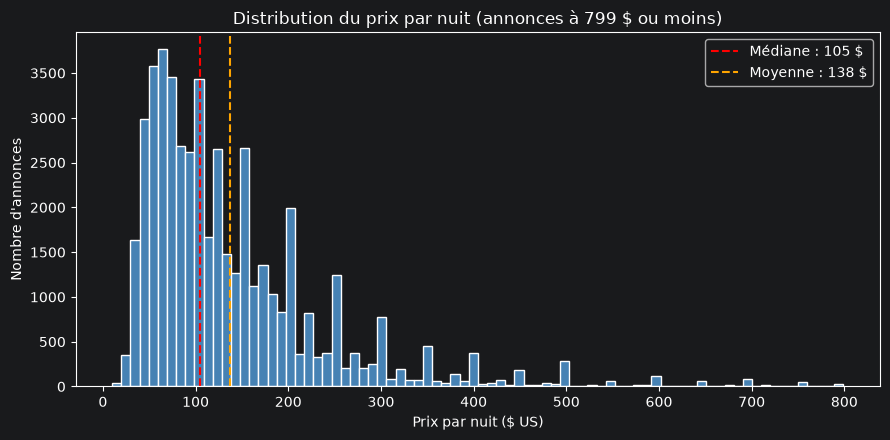

In [7]:
# [SCRUM-29] Q1-T1 · Explorer le prix : forme de la distribution (Figure 1)
print("Asymétrie du prix, annonces brutes     :", round(skew(df["price"]), 2))        # attendu : 19.12
print("Asymétrie du prix, population d'analyse :", round(skew(df_prix["price"]), 2))  # attendu : 2.27

plt.figure(figsize=(9, 4.5))
plt.hist(df_prix["price"], bins=80, color="steelblue", edgecolor="white")
plt.axvline(df_prix["price"].median(), color="red", linestyle="--",
            label="Médiane : " + str(int(df_prix["price"].median())) + " $")
plt.axvline(df_prix["price"].mean(), color="orange", linestyle="--",
            label="Moyenne : " + str(round(df_prix["price"].mean())) + " $")
plt.title("Distribution du prix par nuit (annonces à 799 $ ou moins)")
plt.xlabel("Prix par nuit ($ US)")
plt.ylabel("Nombre d'annonces")
plt.legend()
sauver("fig1_distribution_prix.png")

**Lecture :** la distribution est étirée vers la droite (quelques annonces très chères). La moyenne est donc plus haute que la médiane : pour décrire un prix « typique », on utilise la **médiane**.

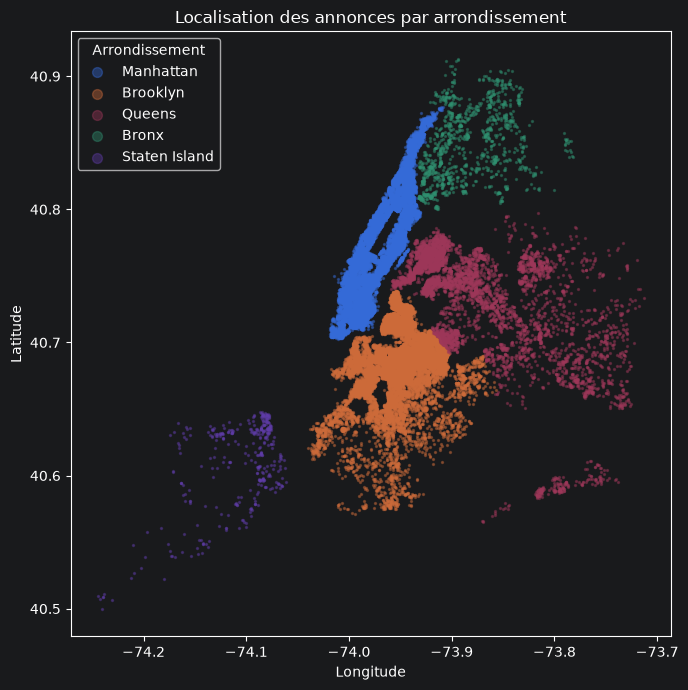

In [8]:
# [SCRUM-29] Q1-T1 · Figure 8 : carte des annonces par arrondissement (longitude x latitude)
plt.figure(figsize=(7, 7))
for arr in ordre_arr:
    sous = df[df["neighbourhood_group"] == arr]
    plt.scatter(sous["longitude"], sous["latitude"], s=2, alpha=0.4, label=arr)
plt.legend(markerscale=5, title="Arrondissement")
plt.title("Localisation des annonces par arrondissement")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
sauver("fig8_carte_annonces.png")

## Étape 4 — Q1 : prix médian par arrondissement et par type de logement
**Responsable : Juba · Story SCRUM-10**

Question : comment le prix médian varie-t-il selon l'arrondissement et le type de logement ? (15 segments)

| Ticket | Sous-tâche | Où dans le notebook |
|---|---|---|
| SCRUM-29 | T1 Explorer price, neighbourhood_group, room_type | Étape 3 (asymétrie, Figure 1), effectifs du tableau ci-dessous |
| SCRUM-30 | T2 Préparer la population d'analyse (48 410) | Étape 3, cellule « Niveau 2 » |
| SCRUM-31 | T3 Statistiques par segment | Cellule « [SCRUM-31] » |
| SCRUM-32 | T4 Évaluer : robustesse (avec et sans extrêmes) | Cellules « [SCRUM-32] » |
| SCRUM-33 | T5 Visualiser et recommander | Cellule « [SCRUM-33] » (Figure 2) et texte d'interprétation |

In [9]:
# [SCRUM-31] Q1-T3 · Statistiques par segment (effectif, moyenne, médiane, Q1, Q3)
groupes = df_prix.groupby(["neighbourhood_group", "type_logement"])["price"]
q1 = pd.DataFrame({
    "effectif": groupes.size(),
    "moyenne": groupes.mean().round(2),
    "mediane": groupes.median(),
    "Q1": groupes.quantile(0.25),
    "Q3": groupes.quantile(0.75),
})
q1

effectif  moyenne  mediane     Q1     Q3
neighbourhood_group type_logement                                             
Bronx               Chambre partagée        59    47.25     40.0   28.0   55.0
                    Chambre privée         650    63.15     53.5   40.0   70.0
                    Logement entier        378   125.20    100.0   80.0  140.0
Brooklyn            Chambre partagée       411    50.77     36.0   30.0   50.0
                    Chambre privée       10101    72.13     65.0   50.0   80.0
                    Logement entier       9480   165.41    145.0  104.0  196.0
Manhattan           Chambre partagée       477    84.09     69.0   49.0   85.0
                    Chambre privée        7930   106.55     90.0   67.0  120.0
                    Logement entier      12905   216.96    190.0  140.0  250.0
Queens              Chambre partagée       195    49.31     37.0   30.0   50.5
                    Chambre privée        3368    67.76     60.0   47.0   75.0
                    Logement entier       2087   140.81    120.0   90.0  165.0
Staten Island       Chambre partagée         9    57.44     30.0   29.0   75.0
                    Chambre privée         188    62.29     50.0   40.0   75.0
                    Logement entier        172   131.09    100.0   75.0  150.0

In [10]:
# [SCRUM-32] Q1-T4 · Segments de moins de 100 annonces (à ne pas utiliser pour conclure)
q1[q1["effectif"] < SEUIL_EFFECTIF]

,,effectif,moyenne,mediane,Q1,Q3
neighbourhood_group,type_logement,,,,,
Bronx,Chambre partagée,59,47.25,40.0,28.0,55.0
Staten Island,Chambre partagée,9,57.44,30.0,29.0,75.0


**Sensibilité :** la médiane change-t-elle si on garde les prix extrêmes (au-dessus de 799 $) ?

In [11]:
# [SCRUM-32] Q1-T4 · Sensibilité : médiane avec et sans les prix > 799 $
tous_les_prix = df[df["price"] > 0]
mediane_avec_extremes = tous_les_prix.groupby(["neighbourhood_group", "type_logement"])["price"].median()
sensibilite = pd.DataFrame({"sans extrêmes": q1["mediane"],
                            "avec extrêmes": mediane_avec_extremes})
sensibilite["écart"] = sensibilite["avec extrêmes"] - sensibilite["sans extrêmes"]
sensibilite

sans extrêmes  avec extrêmes  écart
neighbourhood_group type_logement                                        
Bronx               Chambre partagée           40.0           40.0    0.0
                    Chambre privée             53.5           54.0    0.5
                    Logement entier           100.0          100.0    0.0
Brooklyn            Chambre partagée           36.0           36.0    0.0
                    Chambre privée             65.0           65.0    0.0
                    Logement entier           145.0          145.0    0.0
Manhattan           Chambre partagée           69.0           69.0    0.0
                    Chambre privée             90.0           90.0    0.0
                    Logement entier           190.0          191.0    1.0
Queens              Chambre partagée           37.0           37.0    0.0
                    Chambre privée             60.0           60.0    0.0
                    Logement entier           120.0          120.0    0.0
Staten Island       Chambre partagée           30.0           30.0    0.0
                    Chambre privée             50.0           50.0    0.0
                    Logement entier           100.0          100.0    0.0

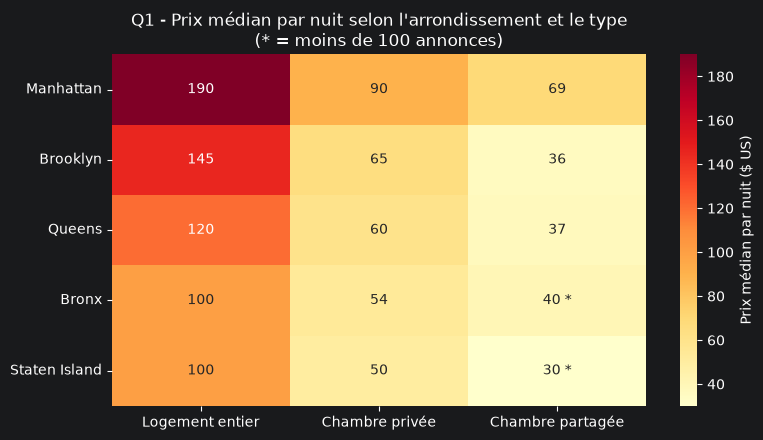

In [12]:
# [SCRUM-33] Q1-T5 · Carte de chaleur (Figure 2) ; une * signale un segment de moins de 100 annonces
matrice = q1["mediane"].unstack().reindex(ordre_arr)[ordre_types]
effectifs = q1["effectif"].unstack().reindex(ordre_arr)[ordre_types]
etiquettes = matrice.round(0).astype("Int64").astype(str)
etiquettes = etiquettes.where(effectifs >= SEUIL_EFFECTIF, etiquettes + " *")

plt.figure(figsize=(8, 4.5))
sns.heatmap(matrice, annot=etiquettes, fmt="", cmap="YlOrRd",
            cbar_kws={"label": "Prix médian par nuit ($ US)"})
plt.title("Q1 - Prix médian par nuit selon l'arrondissement et le type\n"
          "(* = moins de 100 annonces)")
plt.xlabel("")
plt.ylabel("")
sauver("fig2_heatmap_prix.png")

**Interprétation (SCRUM-33) :** le segment le plus cher est Manhattan / logement entier (190 $ la nuit). Parmi les segments d'au moins 100 annonces, le moins cher est Brooklyn / chambre partagée (36 $), soit un rapport de 5,3. Staten Island / chambre partagée affiche 30 $ mais ne repose que sur 9 annonces : on ne s'en sert pas pour comparer.
Le résultat est robuste : garder les prix extrêmes ne change la médiane que de 1 $ au plus (Manhattan / logement entier : 190 $ → 191 $ ; Bronx / chambre privée : 53,50 $ → 54 $). Un `*` signale un segment de moins de 100 annonces.
**Recommandation pour l'investisseur :** comparer Manhattan et Brooklyn en logement entier (190 $ contre 145 $ de prix médian) avant de choisir un segment.

## Étape 5 — Q2 : les 10 quartiers au prix médian le plus élevé
**Responsable : Houmad · Story SCRUM-11**

On ne garde que les quartiers d'au moins 100 annonces, sinon un quartier avec 2 ou 3 annonces chères passerait en tête.

| Ticket | Sous-tâche | Où dans le notebook |
|---|---|---|
| SCRUM-34 | T1 Explorer la variable neighbourhood | Cellule « [SCRUM-34] » |
| SCRUM-35 | T2 Appliquer le seuil de 100 annonces | Cellule « [SCRUM-35] » |
| SCRUM-36 | T3 Agréger et classer (top 10) | Cellule « [SCRUM-36] » |
| SCRUM-37 | T4 Stabilité avec un seuil de 50 | Cellule « [SCRUM-37] » |
| SCRUM-38 | T5 Visualiser et recommander | Cellule « [SCRUM-38] » (Figure 3) |

In [13]:
# [SCRUM-34] Q2-T1 · Explorer neighbourhood : effectifs très inégaux
gq = df_prix.groupby(["neighbourhood", "neighbourhood_group"])["price"]
quartiers = pd.DataFrame({
    "effectif": gq.size(),
    "mediane": gq.median(),
    "Q1": gq.quantile(0.25),
    "Q3": gq.quantile(0.75),
}).reset_index()

print("Nombre de quartiers :", len(quartiers))
print("Quartiers de moins de 100 annonces :", (quartiers["effectif"] < 100).sum())
print("Quartiers de moins de 50 annonces  :", (quartiers["effectif"] < 50).sum())
print("Quartiers de moins de 10 annonces  :", (quartiers["effectif"] < 10).sum())
quartiers["effectif"].describe()

Nombre de quartiers : 220
Quartiers de moins de 100 annonces : 155
Quartiers de moins de 50 annonces  : 122
Quartiers de moins de 10 annonces  : 54


count     220.000000
mean      220.045455
std       532.995410
min         1.000000
25%        10.000000
50%        33.000000
75%       150.750000
max      3904.000000
Name: effectif, dtype: float64

In [14]:
# [SCRUM-35] Q2-T2 · Seuil de stabilité : au moins 100 annonces
print("Quartiers avec au moins 100 annonces :", (quartiers["effectif"] >= 100).sum())
print("Quartiers avec au moins 50 annonces  :", (quartiers["effectif"] >= 50).sum())
quartiers_ok = quartiers[quartiers["effectif"] >= SEUIL_EFFECTIF]

Quartiers avec au moins 100 annonces : 65
Quartiers avec au moins 50 annonces  : 98


In [15]:
# [SCRUM-36] Q2-T3 · Classement : top 10 par prix médian
# À prix médian égal, on classe d'abord le quartier qui a le plus d'annonces
top10 = quartiers_ok.sort_values(["mediane", "effectif", "neighbourhood"], ascending=[False, False, True]).head(10)
top10

,neighbourhood,neighbourhood_group,effectif,mediane,Q1,Q3
196,Tribeca,Manhattan,156,275.5,193.75,358.25
126,Midtown,Manhattan,1503,200.0,144.50,325.00
73,Financial District,Manhattan,738,200.0,145.00,247.00
208,West Village,Manhattan,738,200.0,150.00,250.00
34,Chelsea,Manhattan,1084,195.0,129.00,251.75
91,Greenwich Village,Manhattan,379,195.0,135.00,250.00
177,SoHo,Manhattan,337,194.0,120.00,275.00
136,Murray Hill,Manhattan,478,189.0,149.25,249.75
190,Theater District,Manhattan,279,185.0,100.00,282.50
144,Nolita,Manhattan,249,175.0,109.00,250.00


**Stabilité :** le top 10 change-t-il si on baisse le seuil à 50 annonces ? Et sans aucun seuil ?

In [16]:
# [SCRUM-37] Q2-T4 · Stabilité du classement avec un seuil de 50 annonces
top10_seuil50 = (quartiers[quartiers["effectif"] >= 50]
                 .sort_values(["mediane", "effectif", "neighbourhood"], ascending=[False, False, True]).head(10))
communs = set(top10["neighbourhood"]) & set(top10_seuil50["neighbourhood"])
print("Quartiers communs entre les seuils 100 et 50 :", len(communs), "sur 10")   # attendu : 8
print("Seulement au seuil 100 :", set(top10["neighbourhood"]) - communs)
print("Seulement au seuil 50  :", set(top10_seuil50["neighbourhood"]) - communs)

print("\nSans seuil d'effectif :")
quartiers.sort_values("mediane", ascending=False).head(5)[["neighbourhood", "effectif", "mediane"]]

Quartiers communs entre les seuils 100 et 50 : 8 sur 10
Seulement au seuil 100 : {'Theater District', 'Nolita'}
Seulement au seuil 50  : {'NoHo', 'Flatiron District'}

Sans seuil d'effectif :


,neighbourhood,effectif,mediane
218,Woodrow,1,700.0
196,Tribeca,156,275.5
138,Neponsit,3,274.0
143,NoHo,77,250.0
214,Willowbrook,1,249.0


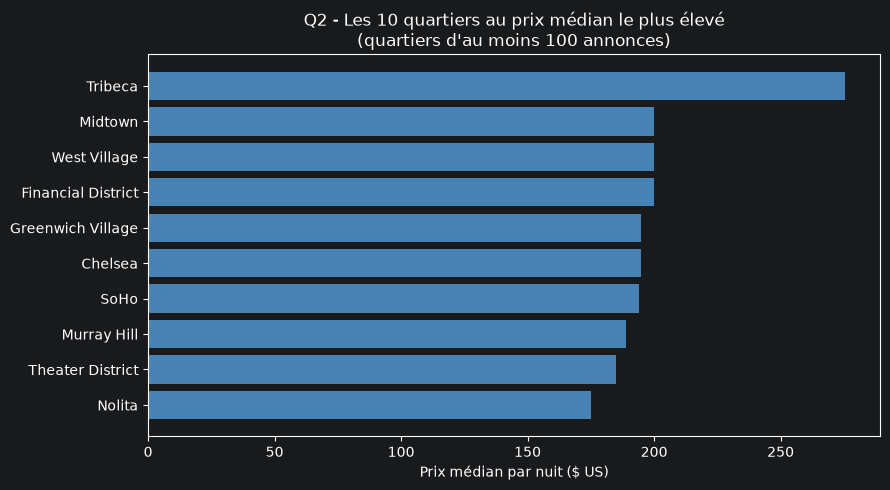

In [17]:
# [SCRUM-38] Q2-T5 · Graphique en barres horizontales (Figure 3)
plt.figure(figsize=(9, 5))
ordre = top10.sort_values("mediane")
plt.barh(ordre["neighbourhood"], ordre["mediane"], color="steelblue")
plt.title("Q2 - Les 10 quartiers au prix médian le plus élevé\n(quartiers d'au moins 100 annonces)")
plt.xlabel("Prix médian par nuit ($ US)")
sauver("fig3_top10_quartiers.png")

**Interprétation (SCRUM-38) :** les dix quartiers au prix médian le plus élevé sont tous à Manhattan. En tête : Tribeca (275,50 $, 156 annonces), puis Midtown, Financial District et West Village (200 $). Le classement est stable : 8 quartiers sur 10 restent les mêmes avec un seuil de 50 annonces. Sans seuil, des quartiers de 1 à 3 annonces passent en tête : c'est la raison du seuil. Cette lecture décrit une association, pas une cause.
**Recommandation :** pour cibler un quartier, partir du top 10 et vérifier son effectif avant de décider.

## Étape 9 — Enregistrer les tableaux (Sprint 2)


In [18]:
q1.to_csv(os.path.join(DOSSIER_SORTIE, "tableau_q1_segments.csv"), encoding="utf-8-sig")
sensibilite.to_csv(os.path.join(DOSSIER_SORTIE, "tableau_q1_sensibilite.csv"), encoding="utf-8-sig")
top10.to_csv(os.path.join(DOSSIER_SORTIE, "tableau_q2_top10_quartiers.csv"), index=False, encoding="utf-8-sig")
print("Terminé. Graphiques et tableaux dans :", DOSSIER_SORTIE, "| données propres dans :", DOSSIER_DONNEES)

Terminé. Graphiques et tableaux dans : ..\outputs | données propres dans : ..\data\processed
